# Editing a scan and closing the reverse-engineering loop

A raw scan needs cleaning before it is measured or rebuilt (roadmap §7.8): `remove_islands` drops the debris, `repair(fill_style=...)` closes the holes the scanner missed with a fan, a minimum-area patch or a faired one, `clip` cuts it by a plane and caps the cut, `offset_surface`, `thicken` and `hollow` give it a wall, `flip_normals` turns a region round, and `decimate(max_deviation=...)` thins it within a stated distance. Rebuilding it as CAD then becomes a loop (roadmap §7.7): `face_support` says which faces of a fitted solid the scan measured and which were inferred, `fit_cad_iterate` re-segments the worst faces until a target is met, `constrain_primitives` makes the fitted primitives exactly parallel, perpendicular or coaxial under control, and `profile_solid` builds a solid from a fitted sketch by revolving or extruding it. See [scan editing](https://loumalouomega.github.io/meshioplusplus/remove_islands), [offset_surface](https://loumalouomega.github.io/meshioplusplus/offset_surface), [the fit_cad loop](https://loumalouomega.github.io/meshioplusplus/fit_cad_loop) and [profile_solid](https://loumalouomega.github.io/meshioplusplus/profile_solid).

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
except ImportError:  # pragma: no cover
    pv = None

WORK = tempfile.mkdtemp()


def render(panels, title, size=(1500, 520), cmap='coolwarm', clim=None, rgb=False):
    """PyVista renders of (mesh, scalar or None, subtitle) panels, embedded
    through matplotlib; a matplotlib scatter when GL is unavailable."""
    try:
        if pv is None:
            raise RuntimeError('no pyvista')
        pl = pv.Plotter(off_screen=True, shape=(1, len(panels)), window_size=size)
        for i, (mesh, scalar, sub) in enumerate(panels):
            pl.subplot(0, i)
            path = os.path.join(WORK, f'view{i}.vtu')
            mp.write(path, mesh)
            grid = pv.read(path)
            if rgb and 'red' in grid.array_names:
                colours = np.stack([grid['red'], grid['green'], grid['blue']], axis=1)
                pl.add_mesh(grid, scalars=colours, rgb=True, show_edges=False)
            elif scalar is not None and scalar in grid.array_names:
                pl.add_mesh(grid, scalars=scalar, cmap=cmap, clim=clim, show_edges=False,
                            scalar_bar_args={'title': scalar})
            else:
                pl.add_mesh(grid, color='#90caf9', show_edges=True, edge_color='#1f4e79',
                            line_width=0.3)
            pl.add_text(sub, font_size=10)
            pl.camera_position = 'iso'
        img = pl.screenshot(return_img=True)
        pl.close()
        plt.figure(figsize=(15, 5.2))
        plt.imshow(img)
        plt.axis('off')
        plt.title(title)
        plt.tight_layout()
        plt.show()
    except Exception as exc:  # head-less GL fallback
        print('PyVista render skipped:', exc)
        fig = plt.figure(figsize=(15, 4.5))
        for i, (mesh, scalar, sub) in enumerate(panels):
            ax = fig.add_subplot(1, len(panels), i + 1, projection='3d')
            p = np.asarray(mesh.points)
            c = mesh.point_data[scalar] if scalar in mesh.point_data else p[:, 2]
            ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=1, c=c, cmap=cmap)
            ax.set_title(sub)
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()

def drop_lists(report):
    return {k: v for k, v in report.items() if not isinstance(v, (list, dict, np.ndarray))}

## A raw scan: debris and a missed cap

A sphere of radius 10 scanned with 0.01 of noise; the scanner missed the cap above z = 9 and picked up three small clusters of debris.

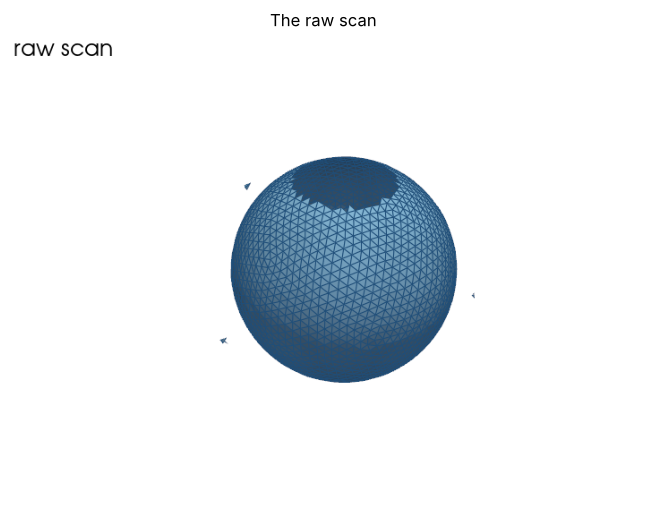

In [2]:
rng = np.random.default_rng(5)
sphere = mp.icosa_sphere(radius=10.0, subdivisions=4)
points = np.asarray(sphere.points) + rng.normal(0, 0.01, np.shape(sphere.points))
tris = sphere.cells[0].data
tris = tris[points[tris].mean(axis=1)[:, 2] < 9.0]
debris_pts, debris_tris = [], []
for k, origin in enumerate([(14, 0, 0), (0, -13, 3), (-12, 6, -6)]):
    debris_pts.append(np.array(origin, float) + rng.normal(0, 0.2, (6, 3)))
    first = len(points) + 6 * k
    debris_tris += [[first + a, first + b, first + c] for a, b, c in [(0, 1, 2), (1, 3, 2), (2, 3, 4), (3, 5, 4)]]
raw = mp.Mesh(np.vstack([points] + debris_pts), [('triangle', np.vstack([tris, debris_tris]))])
render([(raw, None, 'raw scan')], 'The raw scan', size=(700, 520))

## Debris and holes

`remove_islands` labels the edge-connected components and drops those whose diagonal is under a share of the whole (here 5 %); `dry_run=True` only writes the labels. `repair` then fills the cap three ways: `fan` (the default) from the rim's centroid, `flat` a minimum-area triangulation refined to the rim's edge length, and `curved` the same faired with the rim fixed, which follows the sphere.

components 4 | would remove 12 cells
removed 3 islands, 12 cells
fan       49 faces,   1 points added, largest distance from the sphere 1.009
flat     211 faces,  82 points added, largest distance from the sphere 0.909
curved   211 faces,  82 points added, largest distance from the sphere 0.173


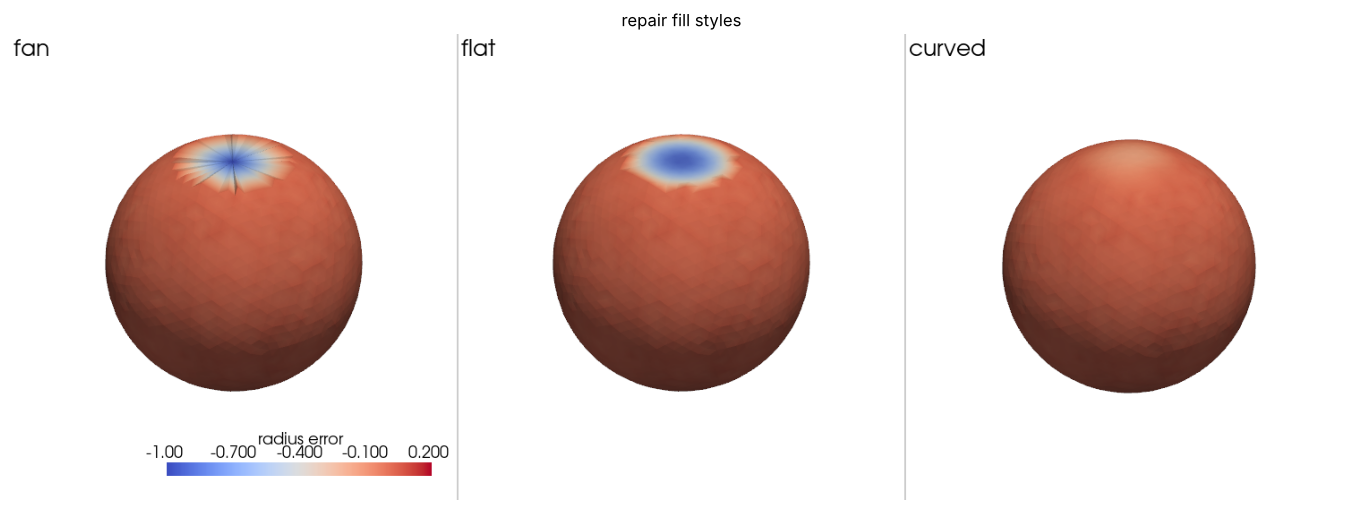

In [3]:
labels, rep = mp.remove_islands(raw, min_diagonal=0.05, dry_run=True, return_report=True)
print('components', rep['num_components'], '| would remove', int(np.sum(labels.cell_data['islands:removed'][0])), 'cells')
clean, rep = mp.remove_islands(raw, min_diagonal=0.05, return_report=True)
print('removed', rep['num_removed'], 'islands,', rep['num_cells_removed'], 'cells')

filled = {}
for style in ('fan', 'flat', 'curved'):
    out, rep = mp.repair(clean, max_hole_edges=1000, fill_style=style, return_report=True)
    added = np.asarray(out.points)[len(clean.points):]
    gap = np.abs(np.linalg.norm(added, axis=1) - 10).max()
    print(f"{style:7s} {rep['num_faces_added']:4d} faces, {rep['num_points_added']:3d} points added, "
          f"largest distance from the sphere {gap:.3f}")
    filled[style] = out
for out in filled.values():
    out.point_data['radius error'] = np.linalg.norm(np.asarray(out.points), axis=1) - 10
render([(filled[s], 'radius error', s) for s in ('fan', 'flat', 'curved')],
       'repair fill styles', clim=(-1, 0.2))
solid = filled['curved']

## Clip, offset, thicken and hollow

`clip` keeps one side of a plane and caps the cut with a triangulation of the section loop, welded to the same nodes the section of `slice` would give. `offset_surface` moves every vertex along its normal by distance / cos(half the normals' spread), the rule `boundary_layer` uses, so flat faces stay at the distance; `thicken` adds the moved copy to an open surface and joins the rims with quads; `hollow` puts an inner wall inside a closed one.

clip: {'num_kept': 3712, 'num_split': 162, 'num_cap_triangles': 160, 'num_loops': 1, 'num_open_chains': 0}
offset: mean radius 10.4991
thicken: 49 rim quads, folded 0
hollow: max move 1.0057 , folded 0
flip_normals: 4116 cells; twice gives the input back: True


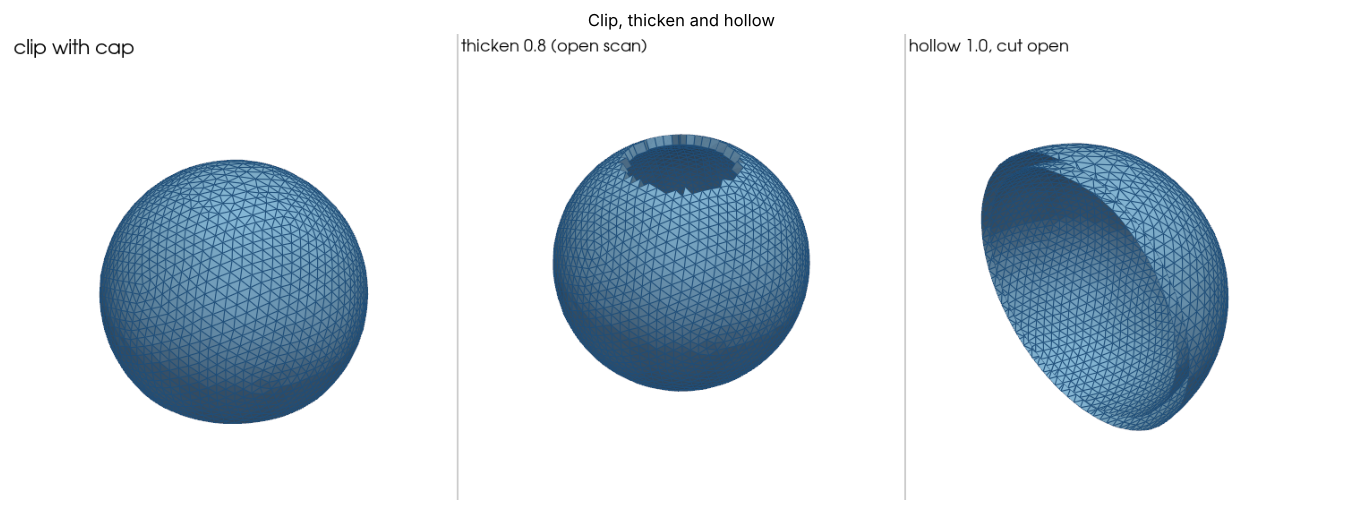

In [4]:
clipped, rep = mp.clip(solid, (0, 0, -5), (0, 0, 1), keep='above', return_report=True)
print('clip:', drop_lists(rep))
offset = mp.offset_surface(solid, 0.5)
print('offset: mean radius', np.linalg.norm(np.asarray(offset.points), axis=1).mean().round(4))
thick, rep = mp.thicken(clean, 0.8, return_report=True)
print('thicken:', rep['num_rim_quads'], 'rim quads, folded', rep['num_folded'])
shell, rep = mp.hollow(solid, 1.0, return_report=True)
print('hollow: max move', round(rep['max_move'], 4), ', folded', rep['num_folded'])
flipped, rep = mp.flip_normals(clipped, return_report=True)
print('flip_normals:', rep['num_flipped'], 'cells; twice gives the input back:',
      np.array_equal(mp.flip_normals(flipped).cells[0].data, clipped.cells[0].data))
render([(clipped, None, 'clip with cap'), (thick, None, 'thicken 0.8 (open scan)'),
        (mp.clip(shell, (0, 0, 0), (1, 0, 0), keep='below', cap=False), None, 'hollow 1.0, cut open')],
       'Clip, thicken and hollow')

## Decimation within a deviation

`decimate(max_deviation=d)` searches the face count by bisection for the coarsest mesh whose two-sided distance to the input stays under `d` for `coverage` of the samples (0.999 by default), and reports what it reached.

4867 -> 1104 triangles, deviation 0.0496 (met: True) after 10 rounds


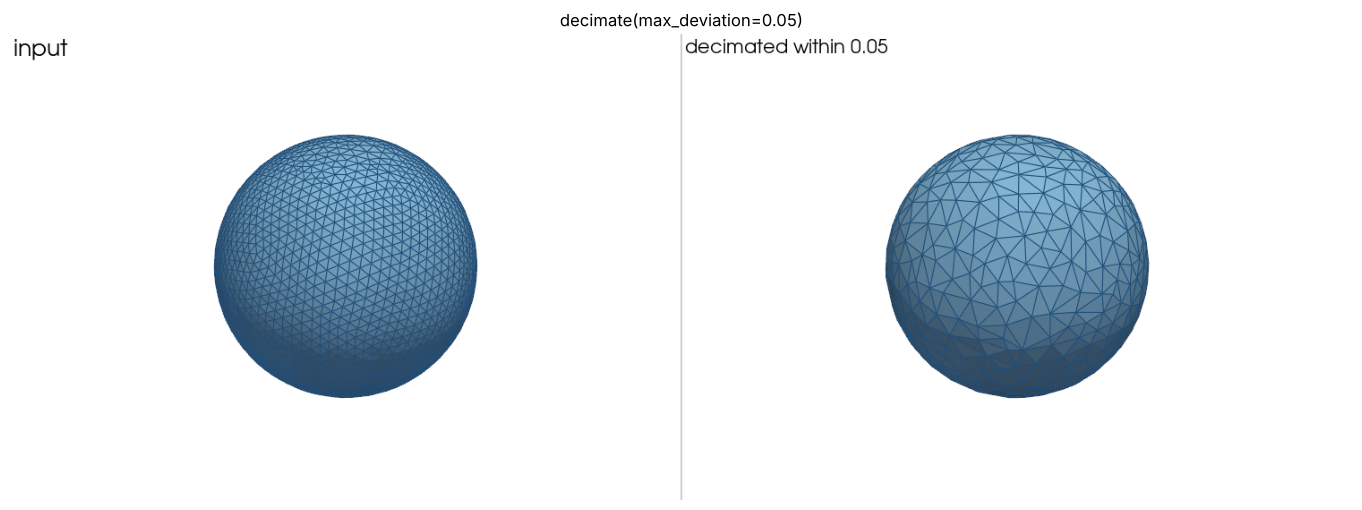

In [5]:
coarse, rep = mp.decimate(solid, max_deviation=0.05, return_report=True)
print(f"{len(solid.cells[0].data)} -> {len(coarse.cells[0].data)} triangles, deviation "
      f"{rep['deviation']:.4f} (met: {rep['deviation_met']}) after {rep['rounds']} rounds")
render([(solid, None, 'input'), (coarse, None, 'decimated within 0.05')], 'decimate(max_deviation=0.05)')

## Which faces did the scan see?

A box scanned from above has no bottom: `repair(record_provenance=True)` fills the hole and tags the filled cells `repair:hole`. After `fit_cad`, `face_support` samples every face of the solid against the scan and classes it `measured`, `partial` or `inferred`: the bottom face came from the fill, not the scan.

measured 5 | partial 0 | inferred 1 | share within tolerance 1.0


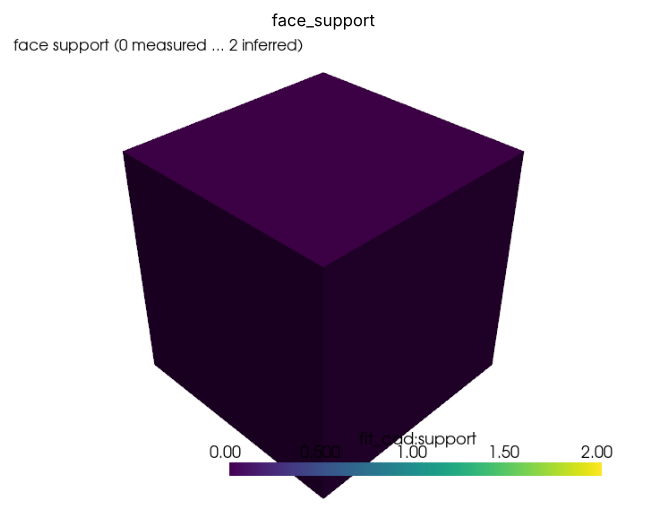

In [6]:
def open_box():
    box = mp.box_surface((4, 4, 4))
    quads = box.cells[0].data
    keep = ~np.all(box.points[quads][:, :, 2] == 0.0, axis=1)
    return mp.repair(mp.Mesh(box.points, [(box.cells[0].type, quads[keep])]), max_hole_edges=0,
                     record_provenance=True)


scan_box = open_box()
cad = mp.fit_cad(mp.fit_primitives(mp.segment(scan_box)), backend='native')
marked, rep = mp.face_support(cad, scan_box, return_report=True)
print('measured', rep['num_measured'], '| partial', rep['num_partial'], '| inferred', rep['num_inferred'],
      '| share within tolerance', rep['share_within'])
render([(marked, 'fit_cad:support', 'face support (0 measured ... 2 inferred)')], 'face_support',
       size=(700, 520), cmap='viridis')

## Iterating until the fit explains the scan

A box whose top bends: one segmentation tolerance merges the bent part with the flat one, and that patch fits nothing. `fit_cad_iterate` fits, finds the worst faces, re-segments their cells with a finer tolerance, refits, and stops on the target, on no improvement or after `max_rounds`.

In [7]:
box = mp.box_surface((8, 8, 8))
p = box.points.copy()
p[:, 2] = p[:, 2] * (1 + 0.06 * np.maximum(0.0, p[:, 0] - 0.5))
bent = mp.Mesh(p, box.cells)
out, rep = mp.fit_cad_iterate(bent, segment_tolerance=0.02, fit_tolerance=1e-3, target_explained=0.999,
                              refine_factor=0.1, backend='native', return_report=True)
for k, r in enumerate(rep['rounds']):
    print(f"round {k}: explained {r['explained']:.3f}, re-segmented faces {r['resegmented']}")
print('stop:', rep['stop_reason'], '| target met:', rep['target_met'])

round 0: explained 0.834, re-segmented faces [5]
round 1: explained 1.000, re-segmented faces []
stop: target | target met: True


## Constraints under control

`constrain_primitives` snaps nearly parallel, perpendicular or coaxial primitives to exact relations, reporting each relation with its angle and distance before the snap; `force` and `forbid` overrule the detection per pair, and a forced relation the data cannot meet is reported as unmet rather than applied.

In [8]:
jitter = np.random.default_rng(3)
cube = mp.box_surface((4, 4, 4))
skin = mp.fit_primitives(mp.segment(mp.Mesh(cube.points + jitter.uniform(-2e-5, 2e-5, cube.points.shape),
                                            cube.cells)))
constrained, rep = mp.constrain_primitives(skin, return_report=True)
print(rep['num_constrained'], 'primitives constrained')
for r in rep['relations'][:6]:
    print(f"  patch {r['patch_a']} - patch {r['patch_b']}: {r['relation']:13s} "
          f"angle residual {r['angle_deg']:.1e} deg, distance {r['distance']:.1e}")
ids = [int(i) for i in skin.field_data['fit:patch_id']]
_, rep = mp.constrain_primitives(skin, force=[(ids[0], ids[1], 'coaxial')], return_report=True)
print('forced but unmet:', rep['unmet'])

5 primitives constrained
  patch 0 - patch 1: parallel      angle residual 6.7e-04 deg, distance 0.0e+00
  patch 0 - patch 2: perpendicular angle residual 7.7e-04 deg, distance 0.0e+00
  patch 2 - patch 3: parallel      angle residual 1.3e-03 deg, distance 0.0e+00
  patch 0 - patch 4: perpendicular angle residual 1.4e-04 deg, distance 0.0e+00
  patch 2 - patch 4: perpendicular angle residual 1.6e-04 deg, distance 0.0e+00
  patch 4 - patch 5: parallel      angle residual 6.2e-04 deg, distance 0.0e+00
forced but unmet: [(0, 1, 'coaxial')]


## A solid from a sketch

A turned part is easier to rebuild from its profile than face by face. The shaft of the sections notebook is clipped at its axis plane, its section fitted to lines and an arc (one closed loop: the half profile and the axis), and `profile_solid` revolves the loop through the OpenCASCADE provider and writes STEP; `deflection` sets the tessellation's chordal sag, and `deviation` compares the solid with the scan. Without a provider it refuses by name.

profile: ['line', 'line', 'line', 'arc', 'line', 'line', 'line']
providers: ['occt']


volume 12850.46, 6 faces, valid True
scan against the solid: rms 0.0052, share within 0.02: 1.0000


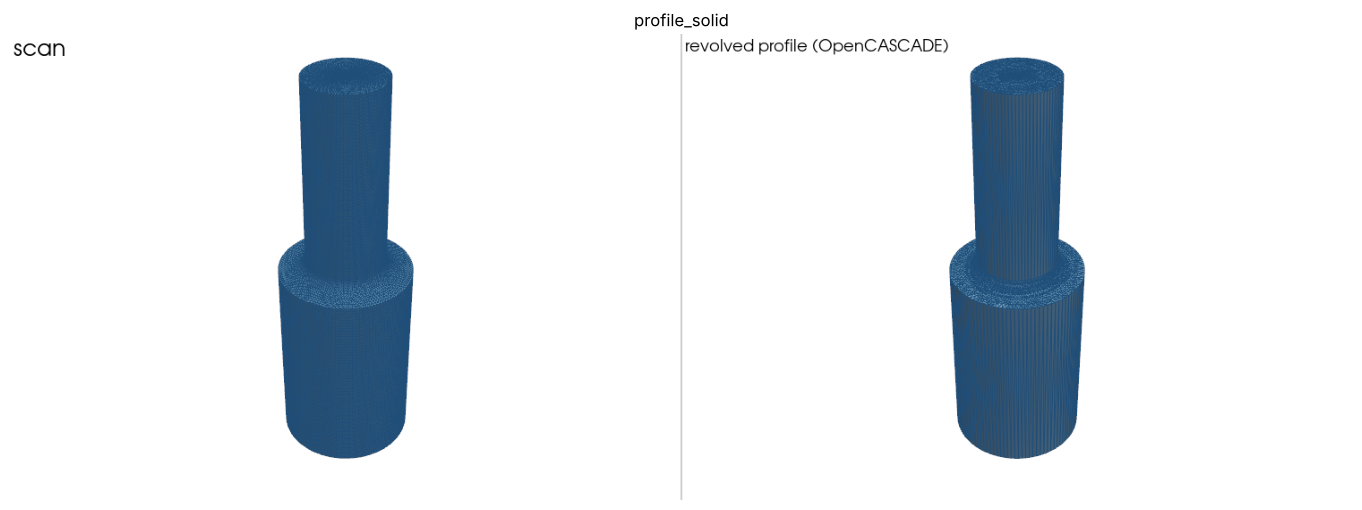

In [9]:
def shaft_profile(step=0.5):
    def line(a, b):
        a, b = np.array(a, float), np.array(b, float)
        n = max(1, int(np.ceil(np.linalg.norm(b - a) / step)))
        return [a + (b - a) * t / n for t in range(n)]
    pts = line((0, 0), (10, 0)) + line((10, 0), (10, 30)) + line((10, 30), (8, 30))
    centre = np.array([8.0, 32.0])
    for k in range(8):
        t = -np.pi / 2 - np.pi / 2 * k / 8
        pts.append(centre + 2 * np.array([np.cos(t), np.sin(t)]))
    pts += line((6, 32), (6, 60)) + line((6, 60), (0, 60)) + [np.array([0.0, 60.0])]
    return np.array(pts)


def revolve(profile, n=128):
    pts, rings = [], []
    for r, z in profile:
        if r < 1e-12:
            rings.append([len(pts)])
            pts.append([0, 0, z])
        else:
            rings.append(list(range(len(pts), len(pts) + n)))
            pts += [[r * np.cos(2 * np.pi * k / n), r * np.sin(2 * np.pi * k / n), z] for k in range(n)]
    tris = []
    for a, b in zip(rings[:-1], rings[1:]):
        for k in range(n):
            if len(a) == 1:
                tris.append([a[0], b[(k + 1) % n], b[k]])
            elif len(b) == 1:
                tris.append([a[k], a[(k + 1) % n], b[0]])
            else:
                tris += [[a[k], a[(k + 1) % n], b[(k + 1) % n]], [a[k], b[(k + 1) % n], b[k]]]
    return mp.Mesh(np.array(pts, float), [('triangle', np.array(tris))])


shaft = revolve(shaft_profile())
shaft.points = np.asarray(shaft.points) + np.random.default_rng(3).normal(0, 0.004, np.shape(shaft.points))
half = mp.clip(shaft, (0, 0, 0), (1, 0, 0), keep='above')
profile, rep = mp.fit_curves(mp.slice(half, (0, 0, 0), (0, 1, 0), chain=True), tolerance=0.02,
                             return_report=True)
print('profile:', [p['type'] for p in rep['pieces']])
print('providers:', mp.profile_solid_providers())
try:
    rebuilt, rep = mp.profile_solid(
        profile, [{'kind': 'revolve', 'axis_origin': (0, 0, 0), 'axis_direction': (0, 0, 1), 'angle': 360}],
        os.path.join(WORK, 'shaft.step'), deflection=0.01, return_report=True)
    print(f"volume {rep['volume']:.2f}, {rep['num_faces']} faces, valid {rep['valid']}")
    dev = mp.deviation(shaft, rebuilt, tolerance=0.02, return_report=True)[1]
    print(f"scan against the solid: rms {dev['rms']:.4f}, share within 0.02: {dev['share_within']:.4f}")
    render([(shaft, None, 'scan'), (rebuilt, None, 'revolved profile (OpenCASCADE)')], 'profile_solid')
except NotImplementedError as exc:
    print('no profile-solid provider in this build:', exc)